# 120개의 강아지 품종을 분류하는 이미지분류 모델 만들기

In [ ]:
#0. 필요한 모듈 사용
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models   # models: 사전훈련된 모델을 불러오는 모듈
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
from PIL import Image

In [ ]:
#1. 이미지 전처리 및 데이터 불러오기
transform= transforms.Compose([
    transforms.Resize((224, 224)),  #모든 이미지를 224x224 크기로 변경 (사전학습된 ResNet152모델이 이 사이즈로 학습했기에.)
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),   # ResNet 모델에서 표준점수에 사용한 평균값
        std=[0.229, 0.224, 0.225]
    )
])

#학습시킬 데이터셋의 경로 준비 (강아지 품종명이 하위폴더명으로 구성된 폴더)
dataset_path="/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/DataSet/dog_images"

dataset= datasets.ImageFolder(
    root= dataset_path,       #하위폴더 구조를 가진 폴더의 경로
    transform= transform
)

In [ ]:
# 데이터셋 확인
print("이미지 개수:", len(dataset))
print("품종 개수:", len(dataset.classes))  # 120개
print("품종 이름:", dataset.classes[:10])

이미지 개수: 20602
품종 개수: 120
품종 이름: ['Afghan_hound', 'African_hunting_dog', 'Airedale', 'American_Staffordshire_terrier', 'Appenzeller', 'Australian_terrier', 'Bedlington_terrier', 'Bernese_mountain_dog', 'Blenheim_spaniel', 'Border_collie']


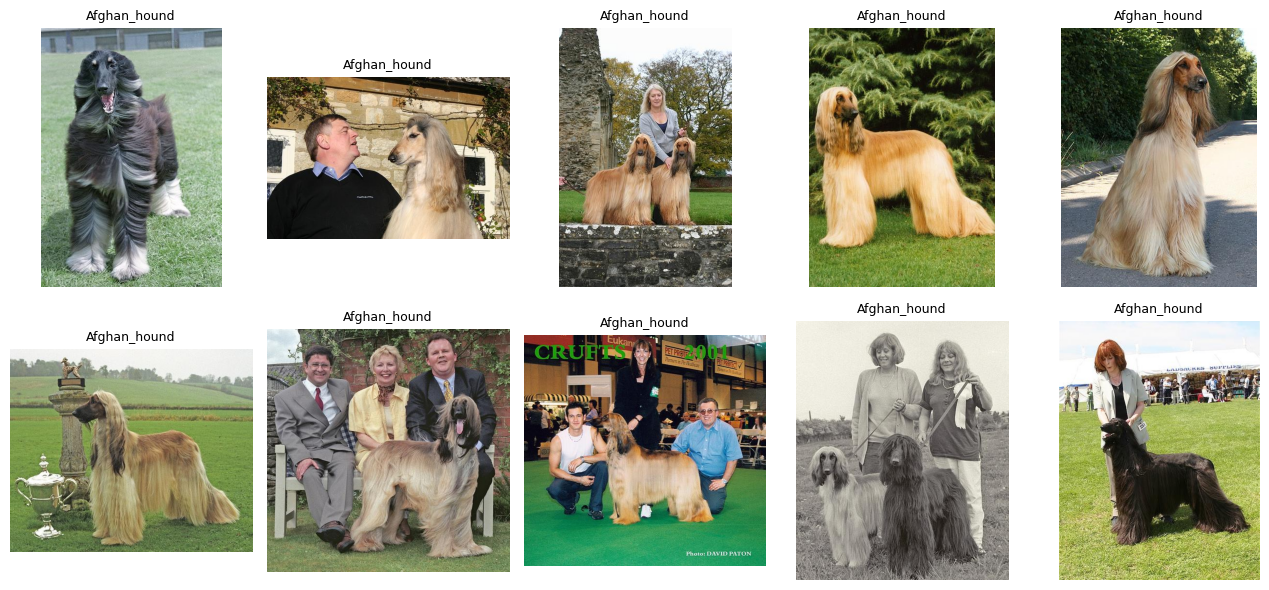

In [ ]:
#4. 이미지 샘플 10개 보기
fig, axes= plt.subplots(2, 5, figsize=(13, 6))
for idx, ax in enumerate(axes.flat):
  image_path, label= dataset.samples[idx]   #이미지파일경로, 라벨명

  # PIL 파이썬 이미지 모듈을 통해서 이미지파일 읽어오기
  image= Image.open(image_path).convert('RGB')

  ax.imshow(image)
  ax.set_title(dataset.classes[label], fontsize=9)
  ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#5. 훈련용과 테스트용 데이터셋 분할 [8:2]
train_dataset, test_dataset= random_split(dataset, [0.8, 0.2], generator= torch.Generator().manual_seed(42))

In [ ]:
#6. 미니배치 단위로 데이터를 읽어주는 데이터로더 생성
#1) 훈련용
train_loader= DataLoader(train_dataset, batch_size=16, shuffle=True)

#2) 테스트용
test_loader= DataLoader(test_dataset, batch_size=16, shuffle=False)

In [ ]:
#7. 사전학습 모델 ResNet152 불러오기

# GPU/CPU 사용환경 설정
device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 모델 불러오기
model= models.resnet152(weights="DEFAULT")  # ImageNet으로 사전학습된 ResNet152의 가중치를 자동으로 다운로드

# 사전 학습된 모델의 구조 확인
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
# 최종 분류기 FC층을 확인 (입력개수,출력개수) -- 출력개수 - 분류명개수 - 1000개
print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


In [ ]:
#8. 전이학습의 핵심코드(특성추출층은 그대로 사용. 분류기 부분만 내 데이터로 바꾸기)
# 기존 ResNet152는 총 클래스개수 : 1000개
# 우리의 Dog 품종은 120개
model.fc= nn.Linear(model.fc.in_features, 120)

#구조가 완성된 후 GPU로 이동
model.to(device)
print(model.fc)

Linear(in_features=2048, out_features=120, bias=True)


In [ ]:
#9. 기존 모델의 가중치 파라미터는 고정시켜놓고 학습시키기
# ResNet의 모든 가중치 고정
for param in model.parameters():
  param.requires_grad= False

# 마지막 FC층만 학습가능하도록..
for param in model.fc.parameters():
  param.requires_grad= True

In [ ]:
# 전이학습이기에 모든 파라미터를 학습하지 않고. 분류기 층만 학습
# 학습할 파라미터의 총 개수 확인 (~-- 모델의 총 파라미터수가 아님)
total_params= sum(p.numel() for p in model.parameters() if p.requires_grad) #<-- if not 으로 바꾸면, 학습하지 않는 개수
print(total_params)

245880


In [ ]:
#10. 손실함수, 최적화 준비
criterion= nn.CrossEntropyLoss()
optimizer= optim.Adam(model.fc.parameters(), lr=0.001) # FC층만 최적화..

In [1]:
#11. 모델학습 -
epochs=3
for epoch in range(epochs):
  model.eval()  #기울기 계산은 되기에 fc층은 정상적으로 학습함.

  epoch_loss= 0      #한 에포크의 손실평균
  epoch_accuracy= 0  #한 에포크의 정확도평균

  #미니배치 단위로 반복하면서 학습
  for images, labels in train_loader:
    images= images.to(device)
    labels= labels.to(device)

    optimizer.zero_grad()
    outputs= model(images)
    loss= criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    epoch_loss += loss.item()
    predictions= outputs.argmax(1)  #행단위 dim=1
    epoch_accuracy += (predictions==labels).sum().item()
  #------------------------------------
  print(f'{epoch}에포크 - 손실:{epoch_loss}, 정확도:{epoch_accuracy/len(train_dataset)}')

NameError: name 'model' is not defined

In [ ]:
#12. 테스트 데이터셋을 이용하여 모델 성능 평가
model.eval()

# 테스트 데이터들 손실, 정확도
test_loss= 0
accuracy= 0

y_true= []  #분류 정답값 저장할 빈 리스트
y_pred= []  #분류 예측값 저장할 빈 리스트

with torch.no_grad():
  for images, labels in test_loader:
    images= images.to(device)  # cpu --> gpu
    labels= labels.to(device)  # cpu --> gpu

    outputs= model(images)
    loss= criterion(outputs, labels) #현재 이미지 묶음(미니배치 16장)에 대한 손실

    prediction= outputs.argmax(1)  # 16장의 이미지들 각 행의 120개 값 중에 가장 큰 값의 인덱스번호

    #정확도. 정답(labels)과 예측(prediction)의 차이 확인(맞춘 개수)
    accuracy += (prediction == labels).sum().item()
    #손실값
    test_loss += loss.item()
  #----------------------------------
  print(epoch, test_loss, accuracy/len(test_dataset))

In [ ]:
# 테스트용 이미지로 모델에게 분류를 요청
#[테스트1] 말티즈 이미지
class_names= model.classes

image_path= "/content/drive/MyDrive/MBCA/딥러닝 YOLO 심화과정/03 CNN 합성곱 신경망/01 Pytorch/Test_Images/dog1.jpg"
image= Image.open(image_path).convert('RGB')
image= transform(image).unsqueeze(0).to(device)

with torch.no_grad():
  outputs= model(image)
  probabilities= torch.softmax(outputs, dim=1)
  confidence, predicted= probabilities.max(1)

print(class_names[predicted])

In [ ]:
# (추가실습) 전이학습 전략을 다르게...
# 모델의 특성 추출층의 일부와 FC층을 학습에 사용

for param in model.parameters():
  param.requires_grad= False

for param in model.layer4.parameters():
  param.requires_grad= True

for param in model.fc.parameters():
  param.requires_grad= True

#최적화
optimizer= optim.Adam([
    {'params':model.layer4.parameters(), 'lr':0.0001},
    {'params':model.fc.parameters(), 'lr':0.0001},
])